In [1]:
import kagglehub
import os 
# Download latest version
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
file_name = os.listdir(path)
print("Path to dataset files:", path)
print(*file_name,sep='\n')


Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Path to dataset files: /kaggle/input/vehicle-dataset-from-cardekho
car data.csv
car details v4.csv
CAR DETAILS FROM CAR DEKHO.csv
Car details v3.csv


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re  

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

## 1. Data Loading & Overview

In [3]:
data = pd.read_csv(os.path.join(path,file_name[3]))

data

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [4]:
data.drop('name',axis=1,inplace=True) # We don't need that
data.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           8128 non-null   int64  
 1   selling_price  8128 non-null   int64  
 2   km_driven      8128 non-null   int64  
 3   fuel           8128 non-null   object 
 4   seller_type    8128 non-null   object 
 5   transmission   8128 non-null   object 
 6   owner          8128 non-null   object 
 7   mileage        7907 non-null   float64
 8   engine         7907 non-null   float64
 9   max_power      7912 non-null   float64
 10  torque         7906 non-null   object 
 11  seats          7907 non-null   float64
dtypes: float64(4), int64(3), object(5)
memory usage: 762.1+ KB


## 2. Exploratory Data Analysis (Raw Data)

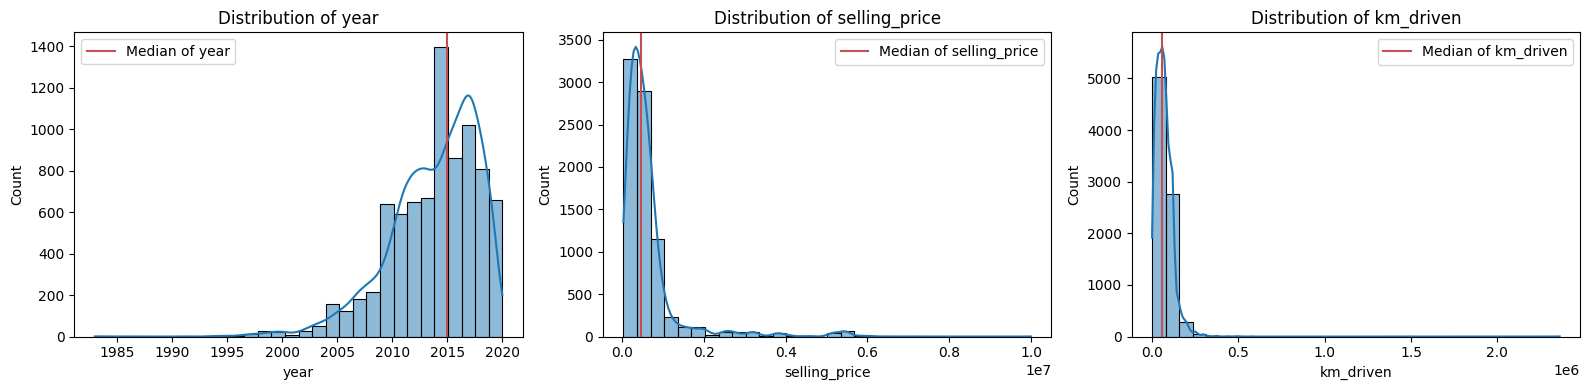

In [13]:
cols = ['year', 'selling_price', 'km_driven']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, cols):
    sns.histplot(data=data, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.axvline(data[col].median(),color='#C44E52',linestyle='-'
               , label=f'Median of {col}')
    ax.legend()

plt.tight_layout()
plt.show()

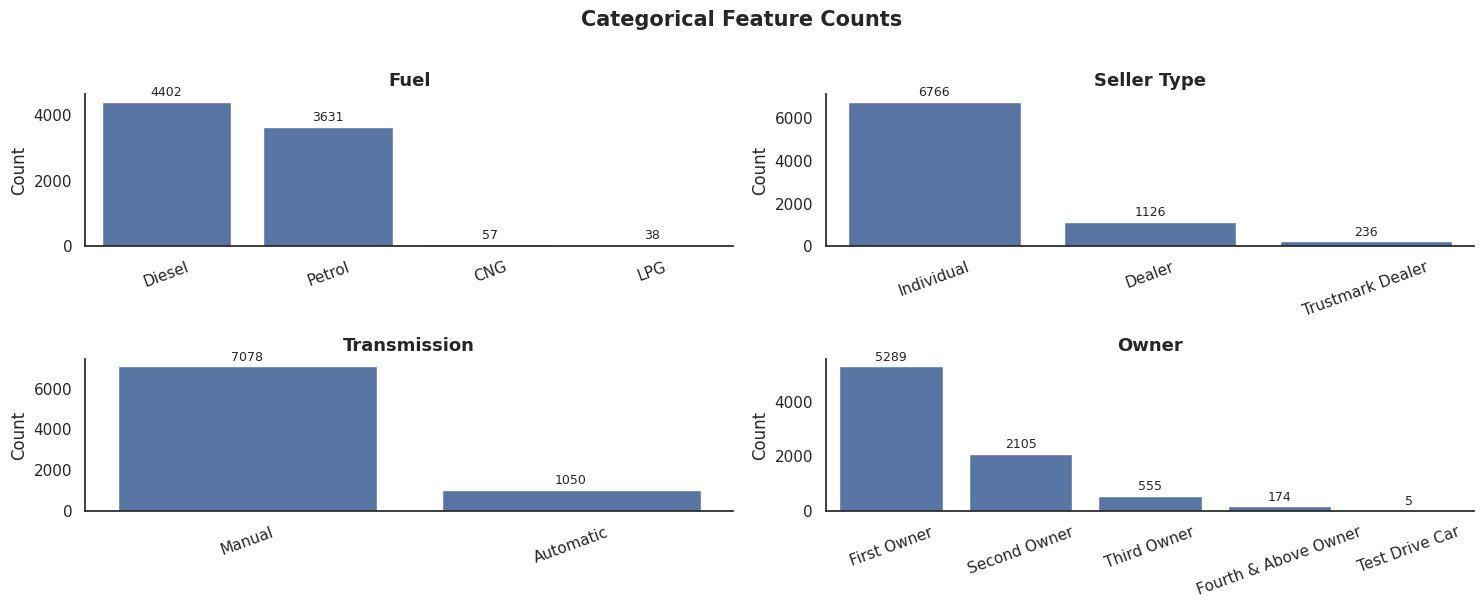

In [20]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']

sns.set_theme(style='white', context='notebook')

fig ,axes = plt.subplots(2,2 ,figsize= (15,6))

for ax, col in zip(axes.flat,cat_cols):
    order = data[col].value_counts().index
    sns.countplot(
        data=data,
        x=col,
        order=order,
        color="#4C72B0",
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(container, fontsize=9, padding=2)

    ax.set_title(col.replace('_', ' ').title(), fontsize=13, weight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=20)
    sns.despine(ax=ax)

fig.suptitle('Categorical Feature Counts', fontsize=15, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Encoding

In [ ]:
data['mileage'] = data['mileage'].str.extract(r'([\d.]+)').astype(float)
data['engine'] = data['engine'].str.extract(r'([\d.]+)').astype(float)
data['max_power'] = data['max_power'].str.extract(r'([\d.]+)').astype(float)

In [ ]:
def parse_torque(s):
    if pd.isna(s):
        return np.nan
    s = str(s).lower().replace(',', '')
    m = re.search(r'(\d+\.?\d*)', s)
    if not m:
        return np.nan
    val = float(m.group(1))
    if 'kgm' in s:
        val *= 9.80665   # kgm -> Nm
    return val

data['torque_nm'] = data['torque'].apply(parse_torque)
data = data.drop(columns='torque')

print(data['torque_nm'].describe())
print(data['torque_nm'].isna().sum())

In [21]:
for col in data.columns:
    uniques = data[col].unique()
    print(f"{col}  |  dtype: {data[col].dtype}  |  nunique: {data[col].nunique()}")
    if len(uniques) <= 20:
        print(sorted(uniques, key=str))
    else:
        print(f"{list(uniques[:10])} ... (first 10 of {len(uniques)})")
    print('-' * 60)

year  |  dtype: int64  |  nunique: 29
[np.int64(2014), np.int64(2006), np.int64(2010), np.int64(2007), np.int64(2017), np.int64(2001), np.int64(2011), np.int64(2013), np.int64(2005), np.int64(2009)] ... (first 10 of 29)
------------------------------------------------------------
selling_price  |  dtype: int64  |  nunique: 677
[np.int64(450000), np.int64(370000), np.int64(158000), np.int64(225000), np.int64(130000), np.int64(440000), np.int64(96000), np.int64(45000), np.int64(350000), np.int64(200000)] ... (first 10 of 677)
------------------------------------------------------------
km_driven  |  dtype: int64  |  nunique: 921
[np.int64(145500), np.int64(120000), np.int64(140000), np.int64(127000), np.int64(45000), np.int64(175000), np.int64(5000), np.int64(90000), np.int64(169000), np.int64(68000)] ... (first 10 of 921)
------------------------------------------------------------
fuel  |  dtype: object  |  nunique: 4
['CNG', 'Diesel', 'LPG', 'Petrol']
---------------------------------

In [22]:
# ordinal: has a real order
owner_map = {
    'Test Drive Car': 0,
    'First Owner': 1,
    'Second Owner': 2,
    'Third Owner': 3,
    'Fourth & Above Owner': 4,
}
data['owner'] = data['owner'].map(owner_map)

# binary
data['transmission'] = data['transmission'].map({'Manual': 0, 'Automatic': 1})

In [23]:
data = pd.get_dummies(data, columns=['fuel', 'seller_type'], drop_first=True, dtype=int)

In [24]:
print(f'nan data : \n {data.isna().sum()}')

print(60*'--')

print(f'duplicated data : \n {data.duplicated().sum()}')

data.dropna(inplace= True)
data.drop_duplicates(inplace= True)


nan data : 
 year                              0
selling_price                     0
km_driven                         0
transmission                      0
owner                             0
mileage                         221
engine                          221
max_power                       216
torque                          222
seats                           221
fuel_Diesel                       0
fuel_LPG                          0
fuel_Petrol                       0
seller_type_Individual            0
seller_type_Trustmark Dealer      0
dtype: int64
------------------------------------------------------------------------------------------------------------------------
duplicated data : 
 1221


In [26]:
data.shape

(6698, 15)

In [31]:
data

,year,selling_price,km_driven,transmission,owner,mileage,engine,max_power,seats,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,torque_nm
0,2014,450000,145500,0,1,23.40,1248.0,74.00,5.0,1,0,0,1,0,190.000000
1,2014,370000,120000,0,2,21.14,1498.0,103.52,5.0,1,0,0,1,0,250.000000
2,2006,158000,140000,0,3,17.70,1497.0,78.00,5.0,0,0,1,1,0,124.544455
3,2010,225000,127000,0,1,23.00,1396.0,90.00,5.0,1,0,0,1,0,219.668960
4,2007,130000,120000,0,1,16.10,1298.0,88.20,5.0,0,0,1,1,0,112.776475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8121,2013,260000,50000,0,2,18.90,998.0,67.10,5.0,0,0,1,1,0,90.000000
8122,2014,475000,80000,0,2,22.54,1396.0,88.73,5.0,1,0,0,1,0,219.700000
8123,2013,320000,110000,0,1,18.50,1197.0,82.85,5.0,0,0,1,1,0,113.700000
8124,2007,135000,119000,0,4,16.80,1493.0,110.00,5.0,1,0,0,1,0,235.359600


## 4. Post-Cleaning Summary Tables

In [32]:
print("Shape:", data.shape)
print("Duplicates:", data.duplicated().sum())

summary = pd.DataFrame({
    'dtype': data.dtypes,
    'missing': data.isna().sum(),
    'missing_%': (data.isna().mean() * 100).round(2),
    'nunique': data.nunique()
})
summary

Shape: (6698, 15)
Duplicates: 0


,dtype,missing,missing_%,nunique
year,int64,0,0.0,27
selling_price,int64,0,0.0,670
km_driven,int64,0,0.0,898
transmission,int64,0,0.0,2
owner,int64,0,0.0,5
mileage,float64,0,0.0,381
engine,float64,0,0.0,121
max_power,float64,0,0.0,318
seats,float64,0,0.0,9
fuel_Diesel,int64,0,0.0,2


In [33]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,6698.0,2013.61,3.90,1994.00,2011.0,2014.00,2017.00,2020.00
selling_price,6698.0,526592.23,524160.98,29999.00,250000.0,420000.00,650000.00,10000000.00
km_driven,6698.0,73408.47,58707.14,1.00,38000.0,68559.50,100000.00,2360457.00
transmission,6698.0,0.09,0.28,0.00,0.0,0.00,0.00,1.00
owner,6698.0,1.50,0.73,0.00,1.0,1.00,2.00,4.00
mileage,6698.0,19.47,4.05,0.00,16.8,19.44,22.50,42.00
engine,6698.0,1431.14,493.34,624.00,1197.0,1248.00,1498.00,3604.00
max_power,6698.0,87.79,31.74,32.80,68.0,81.83,100.00,400.00
seats,6698.0,5.43,0.98,2.00,5.0,5.00,5.00,14.00
fuel_Diesel,6698.0,0.54,0.50,0.00,0.0,1.00,1.00,1.00


In [34]:
print(data.groupby('owner')['selling_price'].agg(['count', 'mean', 'median']).round(0))
print()
print(data.groupby('transmission')['selling_price'].agg(['count', 'mean', 'median']).round(0))

       count       mean     median
owner                             
0          5  4403800.0  5923000.0
1       4160   621057.0   500500.0
2       1885   394004.0   320000.0
3        493   289752.0   229999.0
4        155   231971.0   185000.0

              count       mean    median
transmission                            
0              6123   451811.0  400000.0
1               575  1322916.0  850000.0


In [35]:
fuel_cols = ['fuel_Diesel', 'fuel_LPG', 'fuel_Petrol']
rows = {}
for c in fuel_cols:
    rows[c] = data.loc[data[c] == 1, 'selling_price'].agg(['count', 'mean', 'median'])
rows['CNG (baseline)'] = data.loc[data[fuel_cols].sum(axis=1) == 0, 'selling_price'].agg(['count', 'mean', 'median'])
pd.DataFrame(rows).T.round(0)

,count,mean,median
fuel_Diesel,3650.0,648192.0,525000.0
fuel_LPG,35.0,210886.0,200000.0
fuel_Petrol,2962.0,384076.0,320000.0
CNG (baseline),51.0,317667.0,330000.0


In [36]:
data.corr()['selling_price'].drop('selling_price').sort_values(ascending=False).round(3).to_frame('corr_with_price')

,corr_with_price
max_power,0.692
transmission,0.466
torque_nm,0.443
engine,0.443
year,0.428
fuel_Diesel,0.254
seats,0.158
seller_type_Trustmark Dealer,0.023
fuel_LPG,-0.044
mileage,-0.108


In [37]:
data.groupby('year')['selling_price'].agg(['count', 'mean', 'median']).tail(10).round(0)

,count,mean,median
year,,,
2011,534,315595.0,263500.0
2012,575,353108.0,310000.0
2013,559,452726.0,390000.0
2014,578,512254.0,450000.0
2015,678,588945.0,525000.0
2016,687,654780.0,550000.0
2017,798,733197.0,625000.0
2018,605,867740.0,700000.0
2019,347,949669.0,693000.0


## 5. Feature Engineering

In [38]:
# age of the car (based on the newest year in the data)
ref_year = data['year'].max() + 1
data['car_age'] = ref_year - data['year']

# average yearly usage
data['km_per_year'] = data['km_driven'] / data['car_age']

# engine efficiency: power and torque per cc
data['power_per_cc'] = data['max_power'] / data['engine']
data['torque_per_cc'] = data['torque_nm'] / data['engine']

# log transform for skewed columns
data['log_km_driven'] = np.log1p(data['km_driven'])
data['log_price'] = np.log1p(data['selling_price'])   # target for modeling

# year is now redundant with car_age
data = data.drop(columns='year')

data[['car_age', 'km_per_year', 'power_per_cc', 'torque_per_cc', 'log_km_driven', 'log_price']].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
car_age,6698.0,7.392,3.900,1.000,4.000,7.000,10.000,27.000
km_per_year,6698.0,10739.811,7515.311,0.100,6250.000,9230.769,13333.333,168604.071
power_per_cc,6698.0,0.063,0.012,0.021,0.059,0.064,0.068,0.203
torque_per_cc,6698.0,0.120,0.054,0.049,0.090,0.097,0.152,1.262
log_km_driven,6698.0,10.942,0.814,0.693,10.545,11.135,11.513,14.674
log_price,6698.0,12.890,0.751,10.309,12.429,12.948,13.385,16.118


### Why `log_price`?

Car prices are heavily right-skewed: most cars are cheap and a few are very expensive. Training directly on `selling_price` lets those expensive cars dominate the loss, so the model mostly learns to fit them.

Applying `np.log1p` to the target makes the distribution much more symmetric. The model then minimizes relative (percentage) error instead of absolute error, which treats cheap and expensive cars more evenly.

- The model is trained on `log_price`, and `selling_price` is dropped from the features to avoid target leakage.
- Predictions are converted back with `np.expm1`, so R², MAE and RMSE are reported in the original price units.

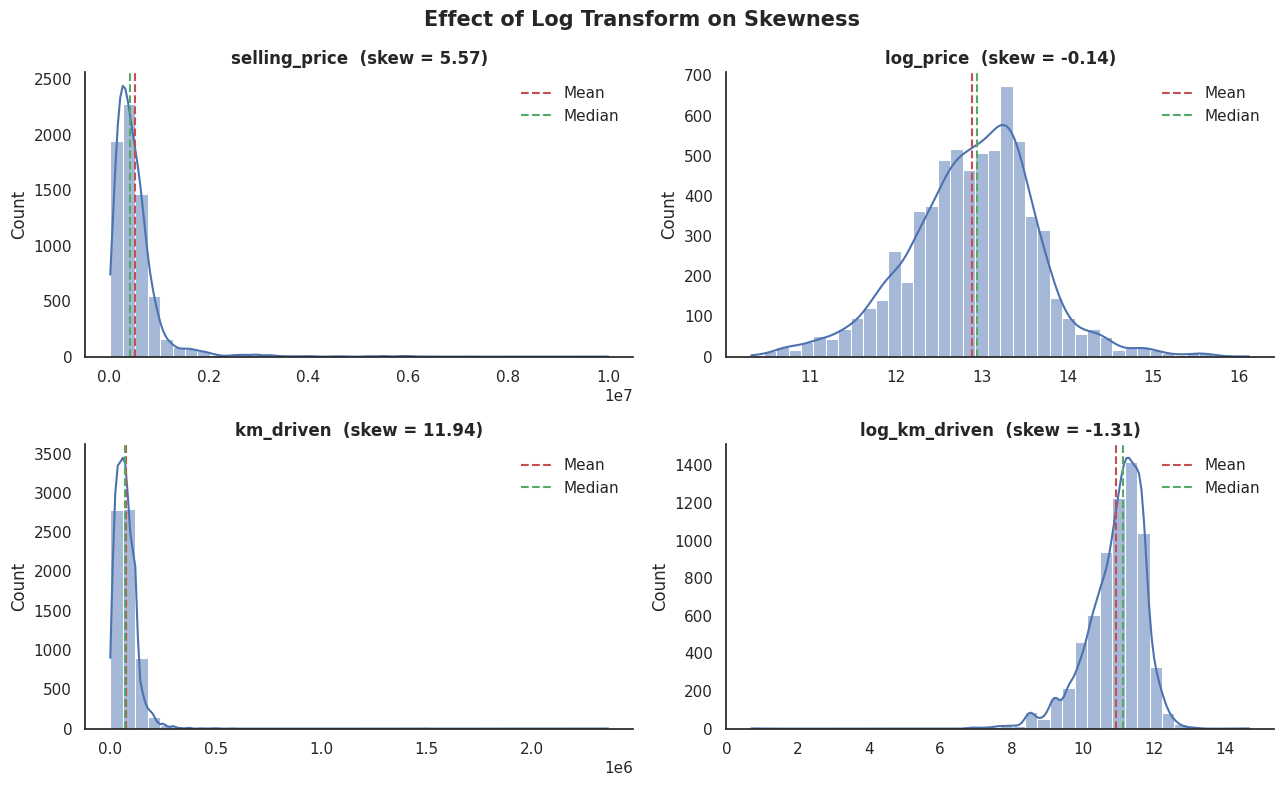

In [44]:
pairs = [
    ('selling_price', 'log_price'),
    ('km_driven', 'log_km_driven'),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for row, (raw, logged) in zip(axes, pairs):
    for ax, col in zip(row, (raw, logged)):
        sns.histplot(data=data, x=col, bins=40, kde=True, color='#4C72B0', edgecolor='white', ax=ax)
        ax.axvline(data[col].mean(), color='#C44E52', linestyle='--', label='Mean')
        ax.axvline(data[col].median(), color='#55A868', linestyle='--', label='Median')
        ax.set_title(f'{col}  (skew = {data[col].skew():.2f})', fontsize=12, weight='bold')
        ax.set_xlabel('')
        ax.legend(frameon=False)
        sns.despine(ax=ax)

fig.suptitle('Effect of Log Transform on Skewness', fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

## 6. Modeling & Evaluation

In [40]:
X = data.drop(columns=['selling_price', 'log_price'])
y = data['log_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# fill missing values with train medians
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [41]:
models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
    'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.expm1(model.predict(X_test))   # back to the real price
    true = np.expm1(y_test)
    results.append({
        'Model': name,
        'R2': r2_score(true, pred),
        'MAE': mean_absolute_error(true, pred),
        'RMSE': np.sqrt(mean_squared_error(true, pred)),
    })

results_df = pd.DataFrame(results).sort_values('R2', ascending=False).round(3)
results_df

,Model,R2,MAE,RMSE
4,LightGBM,0.910,72599.535,152242.854
2,Random Forest,0.909,74735.963,152568.188
3,XGBoost,0.904,72724.367,157156.761
1,Ridge,0.800,112773.715,226509.766
0,Linear Regression,0.800,112778.418,226523.842


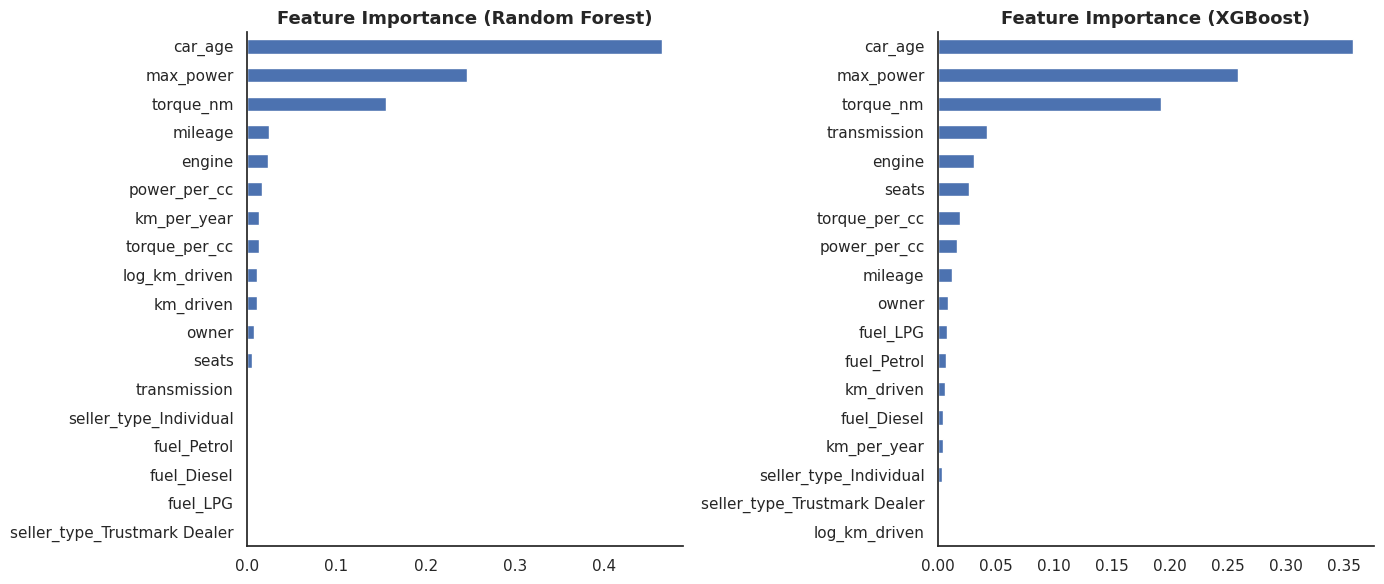

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, ['Random Forest', 'XGBoost']):
    imp = pd.Series(models[name].feature_importances_, index=X.columns).sort_values()
    imp.plot(kind='barh', color='#4C72B0', ax=ax)
    ax.set_title(f'Feature Importance ({name})', fontsize=13, weight='bold')
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()